Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rasters carregados com sucesso. Dimensão: (16505, 21889)
Salvo: /content/drive/MyDrive/pantanal_alagamento/sintese_2019_2021.tif
Salvo: /content/drive/MyDrive/pantanal_alagamento/sintese_2021_2025.tif
Salvo: /content/drive/MyDrive/pantanal_alagamento/sintese_2019_2025.tif
                          periodo                   classe     pixels  \
0                       2019-2021                 Sem dado   16432508   
1                       2019-2021                 Expansão   28026867   
2                       2019-2021       Retração/secamento    7890922   
3                       2019-2021                  Estável  306424321   
4                       2019-2021  Instabilidade crescente    2503327   
5                       2021-2025                 Sem dado   13262481   
6                       2021-2025                 Expansão    3041917   
7             

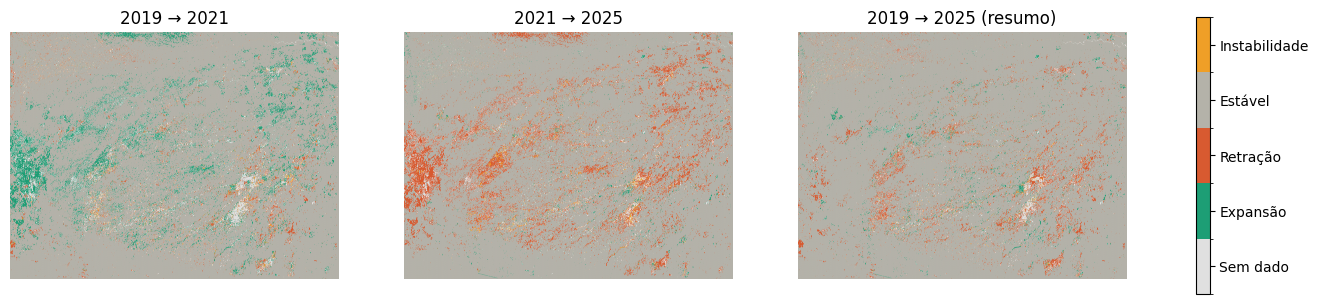

In [ ]:
# ============================================================
# SÍNTESE DE REGIME DE INUNDAÇÃO — Pantanal, 2019 / 2021 / 2025
# Combina: classes hidrológicas + persistência + eventos
#
# Como usar no Google Colab:
# 1. Cole este arquivo inteiro numa célula (ou várias, separando
#    pelos blocos numerados abaixo) e rode em sequência.
# 2. Ajuste a seção "4. CONFIGURAÇÃO" com os caminhos reais dos
#    seus arquivos no Drive e a ordem das suas classes.
# 3. Rode. Os rasters e o CSV de estatísticas saem na mesma pasta
#    dos arquivos de entrada.
# ============================================================

# --- 1. Instalar dependências (só precisa rodar uma vez por sessão) ---
!pip install rasterio -q

# --- 2. Montar o Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import numpy as np
import rasterio
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# ============================================================
# 4. CONFIGURAÇÃO — EDITE ESTA SEÇÃO
# ============================================================

# Pasta onde estão os rasters de entrada (e onde as saídas vão ser salvas)
BASE = '/content/drive/MyDrive/pantanal_alagamento'  # <-- ajuste aqui

# Caminhos dos 9 rasters (3 anos x 3 camadas). Ajuste os nomes dos
# arquivos conforme os seus.
paths = {
    2019: {
        'hydro':   f'{BASE}/classes_hidro_2019.tif',
        'persist': f'{BASE}/persistencia_2019.tif',
        'events':  f'{BASE}/eventos_2019.tif',
    },
    2021: {
        'hydro':   f'{BASE}/classes_hidro_2021.tif',
        'persist': f'{BASE}/persistencia_2021.tif',
        'events':  f'{BASE}/eventos_2021.tif',
    },
    2025: {
        'hydro':   f'{BASE}/classes_hidro_2025.tif',
        'persist': f'{BASE}/persistencia_2025.tif',
        'events':  f'{BASE}/eventos_2025.tif',
    },
}

# Ordem das classes hidrológicas, da mais SECA para a mais ÚMIDA.
# Cada item é (valor_mínimo, valor_máximo, posição_na_escala) — os limites
# são INCLUSIVOS dos dois lados. A posição é o que importa para saber se
# ficou mais úmido ou mais seco (quanto maior, mais úmido/permanente).
# AJUSTE os intervalos conforme a legenda real dos seus dados.
# Se algum valor de pixel não cair em nenhum intervalo, ele vira "sem dado".
class_ranges = [
    (0, 0,   1),   # ex.: nunca alagado
    (1, 2,   2),   # ex.: raro
    (3, 6,   3),   # ex.: sazonal esporádico
    (7, 9,   4),   # ex.: sazonal frequente
    (10, 12, 5),   # ex.: permanente
]

# Limiares para considerar que houve mudança relevante em persistência
# e em eventos, quando a classe hidrológica NÃO mudou (usados para
# detectar "instabilidade crescente" dentro da mesma classe).
PERSIST_THRESHOLD = 1   # meses de queda na maior sequência com água
EVENTS_THRESHOLD  = 1   # aumento no nº de transições alagado/seco

NODATA_OUT = 0  # valor de nodata no raster de saída

# ============================================================
# 5. Funções auxiliares
# ============================================================

def read_raster(path):
    """Lê a banda 1 de um raster e converte nodata em NaN."""
    with rasterio.open(path) as src:
        arr = src.read(1).astype('float64')
        profile = src.profile
        nodata = src.nodata
        if nodata is not None:
            arr[arr == nodata] = np.nan
    return arr, profile


def map_rank_by_range(arr, class_ranges):
    """
    Converte um raster de classes (valores brutos de pixel) para a posição
    ordinal definida em class_ranges = [(min, max, posição), ...].
    Pixels fora de todos os intervalos viram NaN (sem dado).
    """
    rank = np.full(arr.shape, np.nan)
    for lo, hi, r in class_ranges:
        mask = (arr >= lo) & (arr <= hi)
        rank[mask] = r
    return rank


def build_synthesis(year_a, year_b, data, class_ranges, persist_th, events_th, ref_shape):
    """
    Compara dois anos e classifica cada pixel em:
      1 = Expansão da inundação (classe ficou mais úmida)
      2 = Retração / secamento (classe ficou mais seca)
      3 = Estável (mesma classe, persistência e eventos sem mudança relevante)
      4 = Instabilidade crescente (mesma classe, mas persistência caiu
          e/ou eventos aumentaram)
      0 = sem dado válido
    """
    hydro_a, hydro_b = data[year_a]['hydro'], data[year_b]['hydro']
    persist_a, persist_b = data[year_a]['persist'], data[year_b]['persist']
    events_a, events_b = data[year_a]['events'], data[year_b]['events']

    rank_a = map_rank_by_range(hydro_a, class_ranges)
    rank_b = map_rank_by_range(hydro_b, class_ranges)

    delta_rank = rank_b - rank_a
    delta_persist = persist_b - persist_a
    delta_events = events_b - events_a

    out = np.full(ref_shape, NODATA_OUT, dtype='uint8')

    valid = (
        ~np.isnan(rank_a) & ~np.isnan(rank_b) &
        ~np.isnan(persist_a) & ~np.isnan(persist_b) &
        ~np.isnan(events_a) & ~np.isnan(events_b)
    )

    expansao = valid & (delta_rank > 0)
    retracao = valid & (delta_rank < 0)
    mesma_classe = valid & (delta_rank == 0)

    instabilidade = mesma_classe & (
        (delta_persist <= -persist_th) | (delta_events >= events_th)
    )
    estavel = mesma_classe & ~instabilidade

    out[expansao] = 1
    out[retracao] = 2
    out[estavel] = 3
    out[instabilidade] = 4

    return out


def save_raster(arr, out_path, profile):
    with rasterio.open(out_path, 'w', **profile) as dst:
        dst.write(arr, 1)
    print('Salvo:', out_path)


def area_stats(arr, profile, label, class_labels):
    pixel_area_km2 = abs(profile['transform'][0] * profile['transform'][4]) / 1e6
    vals, counts = np.unique(arr, return_counts=True)
    rows = []
    for v, c in zip(vals, counts):
        rows.append({
            'periodo': label,
            'classe': class_labels.get(int(v), str(v)),
            'pixels': int(c),
            'area_km2': round(c * pixel_area_km2, 2),
        })
    return pd.DataFrame(rows)


# ============================================================
# 6. Carregar todos os rasters e checar alinhamento
# ============================================================

data = {}
ref_profile = None
ref_shape = None

for year, files in paths.items():
    data[year] = {}
    for kind, path in files.items():
        arr, profile = read_raster(path)
        data[year][kind] = arr
        if ref_profile is None:
            ref_profile = profile
            ref_shape = arr.shape
        else:
            assert arr.shape == ref_shape, (
                f'Raster {path} tem dimensão {arr.shape}, esperado {ref_shape}. '
                'Todos os rasters precisam estar alinhados '
                '(mesma extensão, resolução e CRS). Se não estiverem, '
                'reamostre com rasterio.warp.reproject antes de continuar.'
            )

print('Rasters carregados com sucesso. Dimensão:', ref_shape)

# ============================================================
# 7. Rodar a síntese para os três períodos
# ============================================================

synthesis_19_21 = build_synthesis(2019, 2021, data, class_ranges, PERSIST_THRESHOLD, EVENTS_THRESHOLD, ref_shape)
synthesis_21_25 = build_synthesis(2021, 2025, data, class_ranges, PERSIST_THRESHOLD, EVENTS_THRESHOLD, ref_shape)
synthesis_19_25 = build_synthesis(2019, 2025, data, class_ranges, PERSIST_THRESHOLD, EVENTS_THRESHOLD, ref_shape)

# ============================================================
# 8. Salvar os rasters de saída
# ============================================================

out_profile = ref_profile.copy()
out_profile.update(dtype='uint8', count=1, nodata=NODATA_OUT)

save_raster(synthesis_19_21, f'{BASE}/sintese_2019_2021.tif', out_profile)
save_raster(synthesis_21_25, f'{BASE}/sintese_2021_2025.tif', out_profile)
save_raster(synthesis_19_25, f'{BASE}/sintese_2019_2025.tif', out_profile)

# ============================================================
# 9. Estatísticas de área por classe
# ============================================================

class_labels = {0: 'Sem dado', 1: 'Expansão', 2: 'Retração/secamento',
                3: 'Estável', 4: 'Instabilidade crescente'}

df_stats = pd.concat([
    area_stats(synthesis_19_21, out_profile, '2019-2021', class_labels),
    area_stats(synthesis_21_25, out_profile, '2021-2025', class_labels),
    area_stats(synthesis_19_25, out_profile, '2019-2025 (resumo do período)', class_labels),
], ignore_index=True)

df_stats.to_csv(f'{BASE}/estatisticas_sintese.csv', index=False)
print(df_stats)

# ============================================================
# 10. Visualização rápida dos três mapas
# ============================================================

cmap = ListedColormap(['#e0e0e0', '#1D9E75', '#D85A30', '#B4B2A9', '#EF9F27'])
bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
norm = BoundaryNorm(bounds, cmap.N)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
titles = ['2019 → 2021', '2021 → 2025', '2019 → 2025 (resumo)']
arrays = [synthesis_19_21, synthesis_21_25, synthesis_19_25]

for ax, arr, title in zip(axes, arrays, titles):
    im = ax.imshow(arr, cmap=cmap, norm=norm)
    ax.set_title(title)
    ax.axis('off')

cbar = fig.colorbar(im, ax=axes, ticks=[0, 1, 2, 3, 4], shrink=0.6)
cbar.ax.set_yticklabels(['Sem dado', 'Expansão', 'Retração', 'Estável', 'Instabilidade'])

plt.savefig(f'{BASE}/mapa_sintese.png', dpi=200, bbox_inches='tight')
plt.show()